## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier


In [2]:
df = pd.read_csv('/content/cumulative.csv')
df

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2654,2655,5652983,K00371.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,1,0,0,...,-98.0,3.611,0.020,-0.014,3.107,0.124,-0.289,299.67615,40.856491,12.193
2655,2656,6471021,K00372.01,Kepler-539 b,CONFIRMED,FALSE POSITIVE,0.006,1,0,0,...,-87.0,4.334,0.132,-0.108,1.111,0.163,-0.148,299.12244,41.866760,12.391
2656,2657,7906671,K03018.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,0,1,...,-166.0,4.339,0.190,-0.190,1.038,0.301,-0.201,296.78445,43.619011,14.720
2657,2658,8709688,K03019.01,NaN,CANDIDATE,CANDIDATE,0.963,0,0,0,...,-76.0,4.296,0.150,-0.113,1.162,0.179,-0.179,298.40137,44.838181,14.927


In [3]:
df.shape

(2659, 50)

In [4]:
df.head()

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [5]:
df.tail()

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
2654,2655,5652983,K00371.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,1,0,0,...,-98.0,3.611,0.020,-0.014,3.107,0.124,-0.289,299.67615,40.856491,12.193
2655,2656,6471021,K00372.01,Kepler-539 b,CONFIRMED,FALSE POSITIVE,0.006,1,0,0,...,-87.0,4.334,0.132,-0.108,1.111,0.163,-0.148,299.12244,41.866760,12.391
2656,2657,7906671,K03018.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,0,1,...,-166.0,4.339,0.190,-0.190,1.038,0.301,-0.201,296.78445,43.619011,14.720
2657,2658,8709688,K03019.01,NaN,CANDIDATE,CANDIDATE,0.963,0,0,0,...,-76.0,4.296,0.150,-0.113,1.162,0.179,-0.179,298.40137,44.838181,14.927
2658,2659,8241079,K03020.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.sample(min(5, len(df)), random_state=42)

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
831,832,8972058,K00159.01,Kepler-115 c,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-117.0,4.315,0.115,-0.115,1.171,0.196,-0.161,297.71185,45.261921,13.431
124,125,5252423,K00825.01,Kepler-237 c,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-146.0,4.574,0.054,-0.041,0.732,0.062,-0.068,283.22141,40.421829,15.289
1431,1432,7273277,K01979.01,Kepler-1035 b,CONFIRMED,CANDIDATE,0.998,0,0,0,...,-87.0,4.461,0.040,-0.120,0.992,0.152,-0.065,289.04221,42.882488,12.987
1613,1614,9536692,K01948.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,1,...,-155.0,4.455,0.108,-0.148,0.882,0.153,-0.114,295.84900,46.181290,15.551
700,701,10586208,K01308.01,Kepler-811 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-101.0,4.152,0.217,-0.093,1.354,0.211,-0.317,285.42429,47.834610,13.971


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2659 entries, 0 to 2658
Data columns (total 50 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rowid              2659 non-null   int64  
 1   kepid              2659 non-null   int64  
 2   kepoi_name         2659 non-null   object 
 3   kepler_name        1437 non-null   object 
 4   koi_disposition    2659 non-null   object 
 5   koi_pdisposition   2659 non-null   object 
 6   koi_score          2563 non-null   float64
 7   koi_fpflag_nt      2659 non-null   int64  
 8   koi_fpflag_ss      2659 non-null   int64  
 9   koi_fpflag_co      2659 non-null   int64  
 10  koi_fpflag_ec      2659 non-null   int64  
 11  koi_period         2659 non-null   float64
 12  koi_period_err1    2624 non-null   float64
 13  koi_period_err2    2624 non-null   float64
 14  koi_time0bk        2659 non-null   float64
 15  koi_time0bk_err1   2624 non-null   float64
 16  koi_time0bk_err2   2624 

In [8]:
df.describe()

,rowid,kepid,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
count,2659.000000,2.659000e+03,2563.000000,2659.000000,2659.000000,2659.000000,2659.000000,2659.000000,2624.000000,2624.000000,...,2611.000000,2628.000000,2620.000000,2620.000000,2628.000000,2620.000000,2620.000000,2658.000000,2658.000000,2658.000000
mean,1330.000000,7.755409e+06,0.734535,0.023317,0.150432,0.151185,0.083866,75.378032,0.000167,-0.000167,...,-141.387591,4.390582,0.094655,-0.120341,1.277169,0.238542,-0.224827,291.743892,43.907462,14.459417
std,767.731507,2.682357e+06,0.425445,0.150937,0.357562,0.358296,0.277239,2521.719177,0.000911,0.000911,...,62.261763,0.322456,0.095573,0.072217,3.362252,0.638967,1.029005,4.784270,3.634836,1.301526
min,1.000000,7.574500e+05,0.000000,0.000000,0.000000,0.000000,0.000000,0.293630,0.000000,-0.028170,...,-1005.000000,0.650000,0.000000,-0.748000,0.116000,0.000000,-33.660000,280.258390,36.577381,6.974000
25%,665.500000,5.634139e+06,0.356500,0.000000,0.000000,0.000000,0.000000,3.613072,0.000006,-0.000095,...,-179.000000,4.309750,0.038000,-0.180000,0.809750,0.084000,-0.161000,288.178913,40.853859,13.742500
50%,1330.000000,8.073806e+06,0.997000,0.000000,0.000000,0.000000,0.000000,8.742920,0.000025,-0.000025,...,-134.000000,4.468000,0.063000,-0.112000,0.950000,0.184000,-0.094000,292.044495,43.900951,14.830500
75%,1994.500000,9.904032e+06,1.000000,0.000000,0.000000,0.000000,0.000000,22.044256,0.000095,-0.000006,...,-87.000000,4.556000,0.125000,-0.064000,1.182250,0.281000,-0.061000,295.565542,46.790748,15.401000
max,2659.000000,1.264482e+07,1.000000,1.000000,1.000000,1.000000,1.000000,129995.778400,0.028170,0.000000,...,0.000000,5.283000,0.917000,0.000000,101.451000,20.714000,0.000000,301.720760,51.761822,18.498000


In [9]:
df.describe(include="object")

,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_tce_delivname
count,2659,1437,2659,2659,2574
unique,2659,1437,3,2,3
top,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,q1_q17_dr25_tce
freq,1,1,1436,1966,2562


In [10]:
print("Number of duplicated rows:", df.duplicated().sum())
print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values").query("`Missing Values` > 0"))

Number of duplicated rows: 0

Missing values per column:


,Missing Values
kepler_name,1222
koi_score,96
koi_period_err1,35
koi_period_err2,35
koi_time0bk_err1,35
koi_time0bk_err2,35
koi_impact,30
koi_impact_err1,35
koi_impact_err2,35
koi_duration_err1,35


In [11]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})
missing_summary = missing_summary[missing_summary["Missing Values"] > 0]
display(missing_summary.sort_values("Missing Percentage", ascending=False))

,Missing Values,Missing Percentage
koi_teq_err2,2659,100.000000
koi_teq_err1,2659,100.000000
kepler_name,1222,45.957127
koi_score,96,3.610380
koi_tce_delivname,85,3.196690
koi_tce_plnt_num,85,3.196690
koi_steff_err2,48,1.805190
koi_slogg_err2,39,1.466717
koi_srad_err1,39,1.466717
koi_srad_err2,39,1.466717


## 4. Check Data Types and Categories

In [12]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numerical_columns)
print("\nCategorical columns:", categorical_columns)

Numerical columns: ['rowid', 'kepid', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag']

Categorical columns: ['kepoi_name', 'kepler_name', 'koi_disposition', 'koi_pdisposition', 'koi_tce_delivname']


Value Count

In [13]:
for column in categorical_columns:
    print(f"\\n{column}")
    print(df[column].value_counts(dropna=False).head(20))

\nkepoi_name
kepoi_name
K00752.01    1
K00752.02    1
K00753.01    1
K00754.01    1
K00755.01    1
K00756.01    1
K00756.02    1
K00756.03    1
K00114.01    1
K00757.01    1
K00001.01    1
K00002.01    1
K00010.01    1
K00112.02    1
K00742.01    1
K00743.01    1
K00744.01    1
K00745.01    1
K00746.01    1
K00747.01    1
Name: count, dtype: int64
\nkepler_name
kepler_name
NaN              1222
Kepler-368 b        1
Kepler-1103 b       1
Kepler-1102 b       1
Kepler-1101 b       1
Kepler-1100 b       1
Kepler-1200 b       1
Kepler-1199 b       1
Kepler-1198 b       1
Kepler-1164 b       1
Kepler-1163 b       1
Kepler-1161 b       1
Kepler-367 c        1
Kepler-367 b        1
Kepler-1099 b       1
Kepler-121 b        1
Kepler-1098 b       1
Kepler-1097 b       1
Kepler-1096 b       1
Kepler-1197 b       1
Name: count, dtype: int64
\nkoi_disposition
koi_disposition
CONFIRMED         1436
FALSE POSITIVE     671
CANDIDATE          552
Name: count, dtype: int64
\nkoi_pdisposition
koi_pdispo

::## 5. Exploratory Data Analysis

Target Distribution

,Count
koi_disposition,
CONFIRMED,1436
FALSE POSITIVE,671
CANDIDATE,552


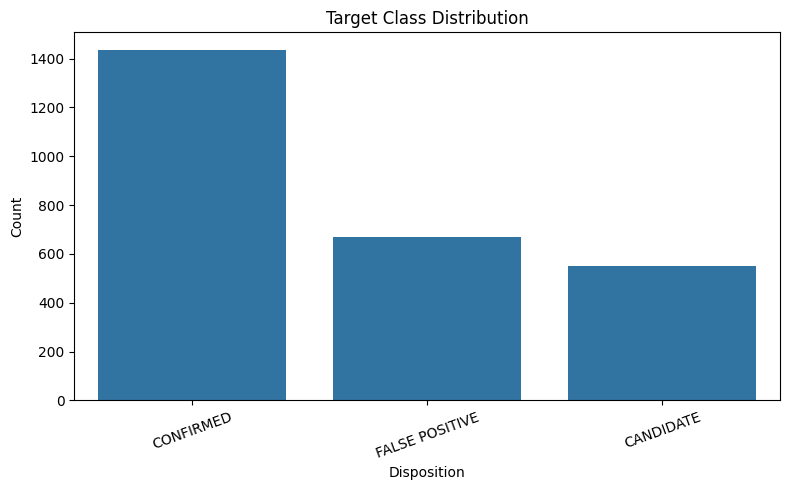

In [14]:
TARGET = "koi_disposition"

if TARGET not in df.columns:
    raise KeyError(f"Target column '{TARGET}' was not found in the dataset.")

display(df[TARGET].value_counts(dropna=False).to_frame("Count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index)
plt.title("Target Class Distribution")
plt.xlabel("Disposition")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Numerical Feature Distributions

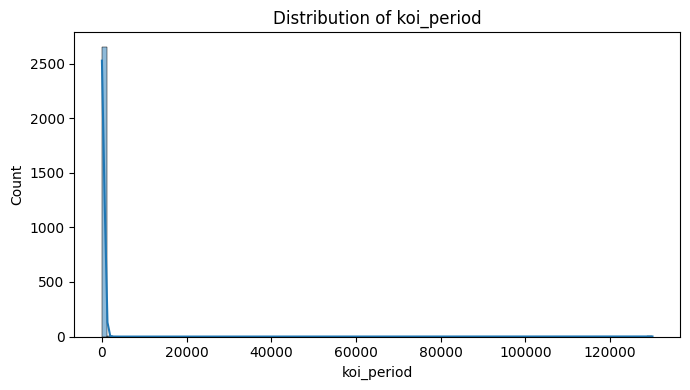

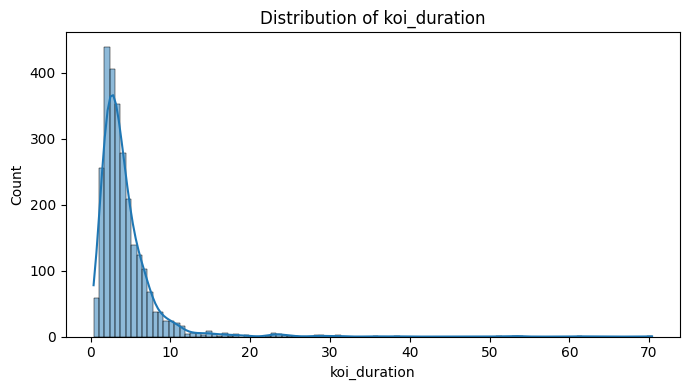

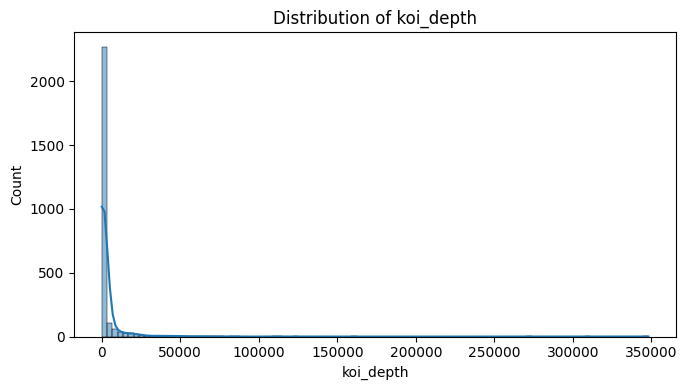

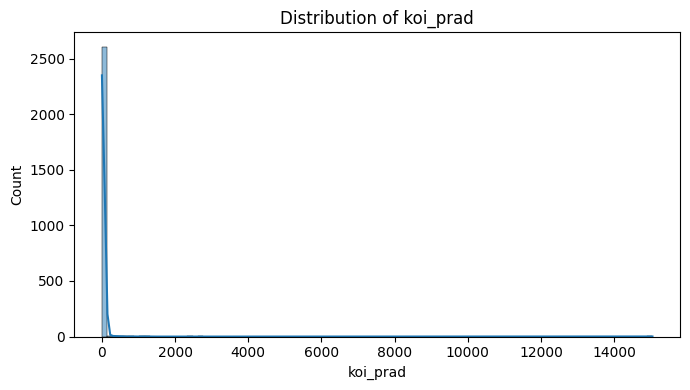

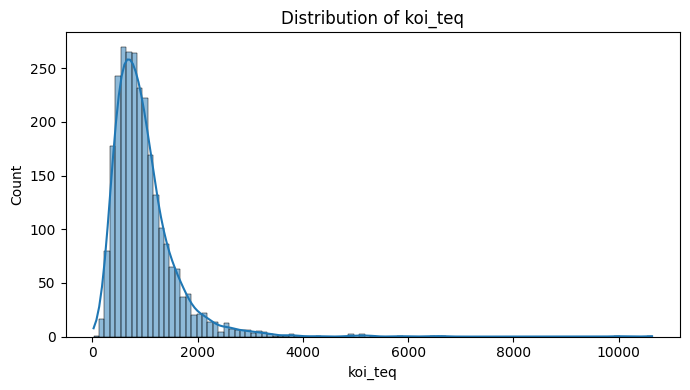

In [15]:
candidate_numerical_features = [
    "koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_teq"
]
numerical_features = [
    column for column in candidate_numerical_features
    if column in df.columns and pd.api.types.is_numeric_dtype(df[column])
]

for column in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=column, kde=True)
    plt.title(f"Distribution of {column}")
    plt.tight_layout()
    plt.show()

###  Categorical Feature Analysis

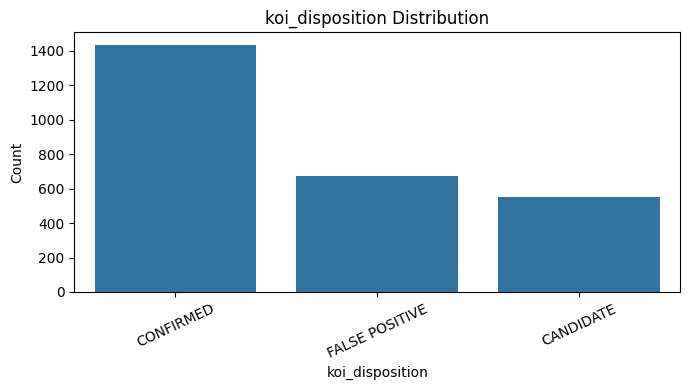

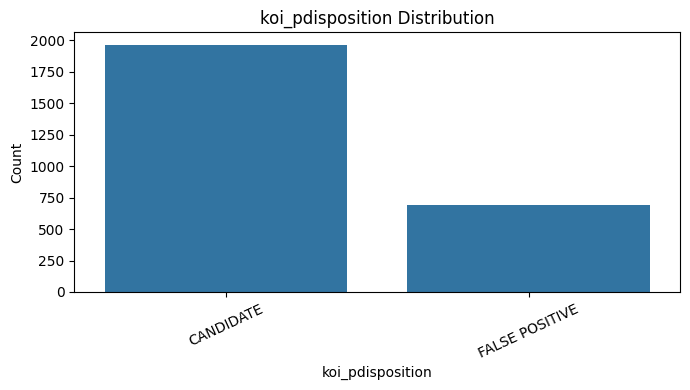

In [16]:
candidate_categorical_features = ["koi_disposition", "koi_pdisposition"]
categorical_features = [
    column for column in candidate_categorical_features if column in df.columns
]

for column in categorical_features:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=column, order=df[column].value_counts().index)
    plt.title(f"{column} Distribution")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

###Correlation Heatmap

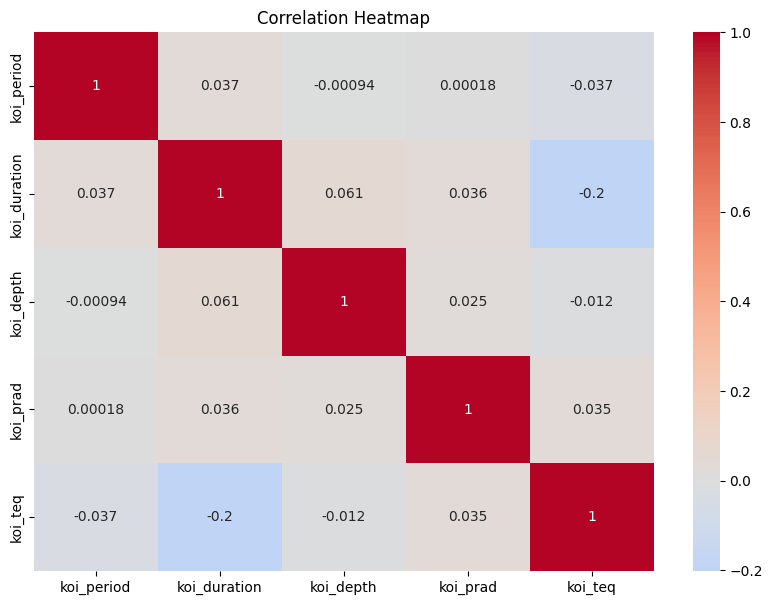

In [17]:
correlation = df[numerical_features].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')
plt.show()

###Numerical Features vs Target

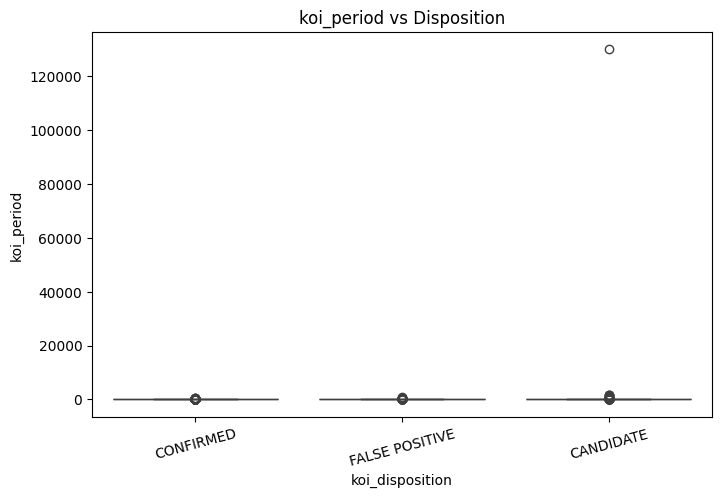

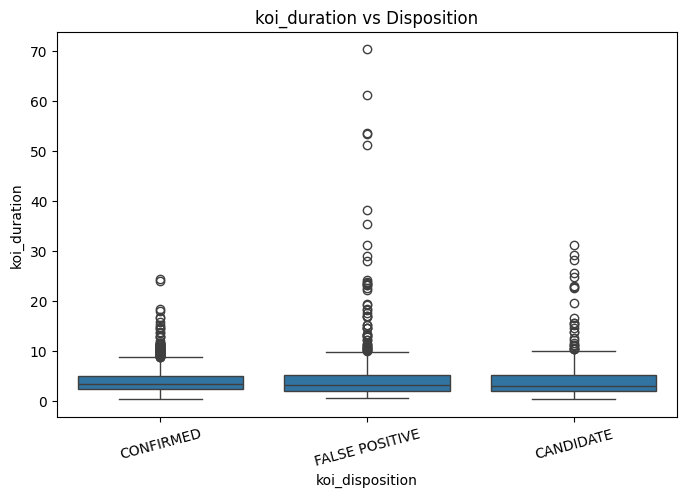

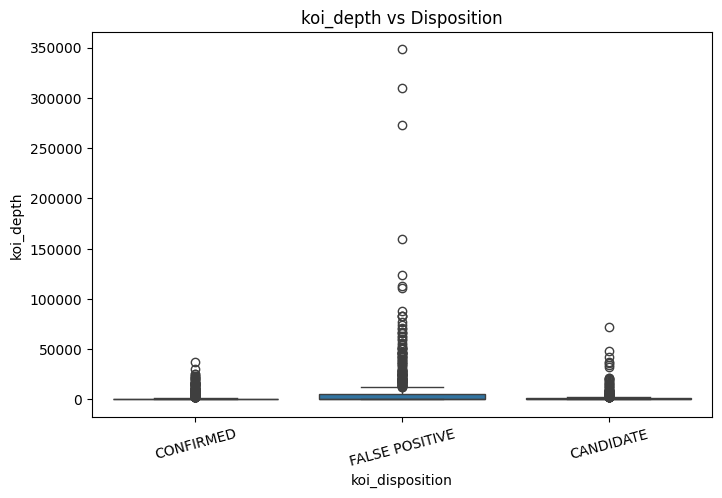

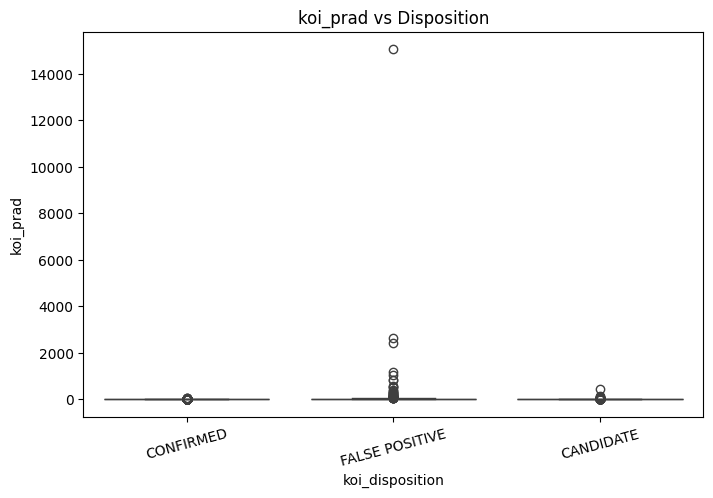

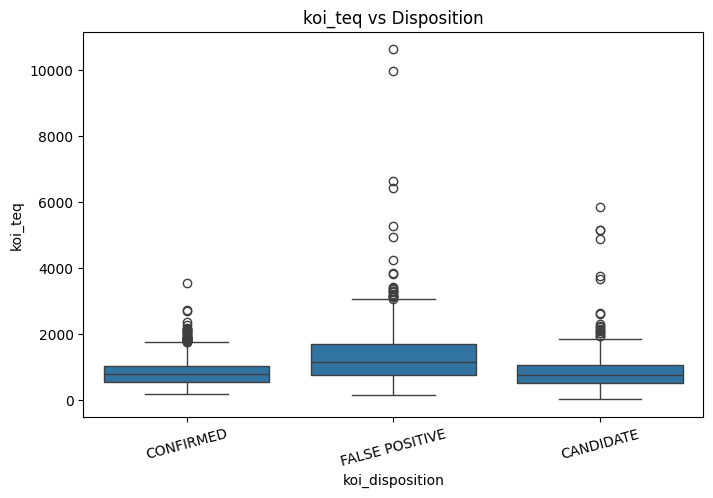

In [18]:
for col in numerical_features:

    plt.figure(figsize=(8,5))

    sns.boxplot(
        data=df,
        x='koi_disposition',
        y=col
    )

    plt.title(f'{col} vs Disposition')
    plt.xticks(rotation=15)
    plt.show()

## 6. Data Cleaning

In [19]:
drop_columns = [
    "rowid",
    "kepid",
    "kepoi_name",
    "kepler_name",
    "koi_pdisposition",     #Data leakage
    "koi_score",         # Validation score; excluded to avoid leakage.
    "koi_fpflag_nt",
    "koi_fpflag_ss",
    "koi_fpflag_co",
    "koi_fpflag_ec",
    "koi_tce_delivname"
]

df_clean = df.drop(columns=drop_columns, errors="ignore").copy()

df_clean = df_clean.dropna(subset=[TARGET])
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Original shape:", df.shape)
print("Shape after cleaning:", df_clean.shape)
print("Target classes:")
print(df_clean[TARGET].value_counts())

Original shape: (2659, 50)
Shape after cleaning: (2659, 39)
Target classes:
koi_disposition
CONFIRMED         1436
FALSE POSITIVE     671
CANDIDATE          552
Name: count, dtype: int64


###  Review Missing Values

In [20]:
missing_after_cleaning = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": df_clean.isnull().mean() * 100
})
missing_after_cleaning = missing_after_cleaning[
    missing_after_cleaning["Missing Values"] > 0
]
display(missing_after_cleaning.sort_values("Missing Percentage", ascending=False))

,Missing Values,Missing Percentage
koi_teq_err1,2659,100.000000
koi_teq_err2,2659,100.000000
koi_tce_plnt_num,85,3.196690
koi_steff_err2,48,1.805190
koi_slogg_err2,39,1.466717
koi_srad_err1,39,1.466717
koi_steff_err1,39,1.466717
koi_slogg_err1,39,1.466717
koi_srad_err2,39,1.466717
koi_period_err1,35,1.316284


### Remove Columns with No Useful Values

In [21]:
# Drop columns that are completely empty.
all_missing_columns = df_clean.columns[df_clean.isnull().all()].tolist()
print("Completely empty columns:", all_missing_columns)

df_clean = df_clean.drop(columns=all_missing_columns)
print("Shape after dropping completely empty columns:", df_clean.shape)

Completely empty columns: ['koi_teq_err1', 'koi_teq_err2']
Shape after dropping completely empty columns: (2659, 37)


## 7. Separate Features and Target

In [22]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
display(y.value_counts())

Features shape: (2659, 36)
Target shape: (2659,)

Target distribution:


,count
koi_disposition,
CONFIRMED,1436
FALSE POSITIVE,671
CANDIDATE,552


 8. Check Outliers


In [23]:
outlier_cols = [
    'koi_depth',
    'koi_period',
    'koi_model_snr',
    'koi_prad',
    'koi_insol',
    'koi_duration'
]

Q1 = X[outlier_cols].quantile(0.25)
Q3 = X[outlier_cols].quantile(0.75)
IQR = Q3 - Q1

outliers = ((X[outlier_cols] < Q1 - 1.5 * IQR) |
            (X[outlier_cols] > Q3 + 1.5 * IQR)).sum()

print(outliers)

koi_depth        406
koi_period       313
koi_model_snr    377
koi_prad         490
koi_insol        370
koi_duration     148
dtype: int64


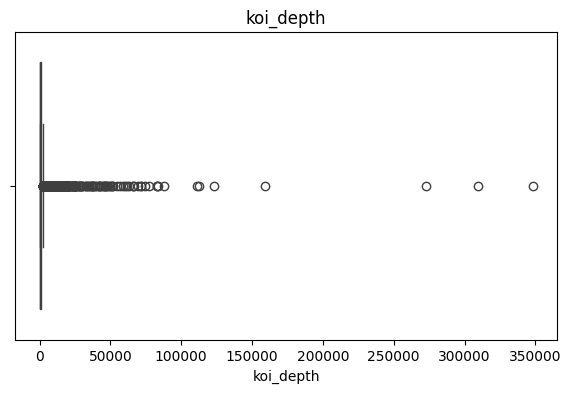

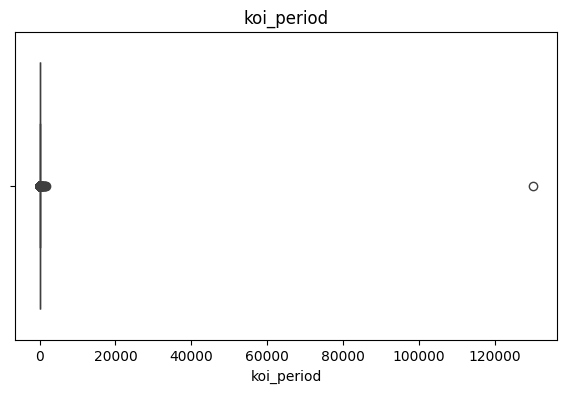

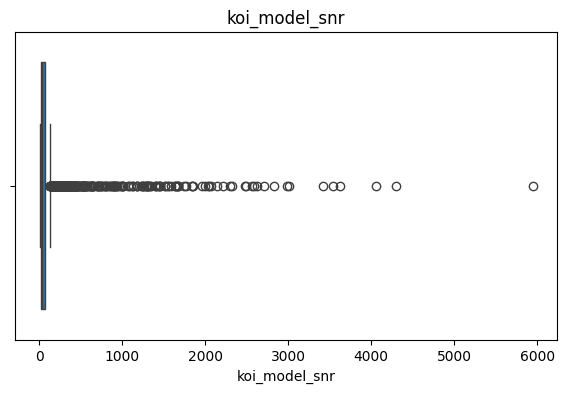

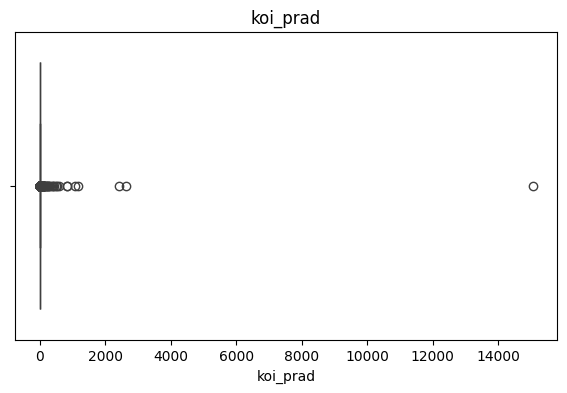

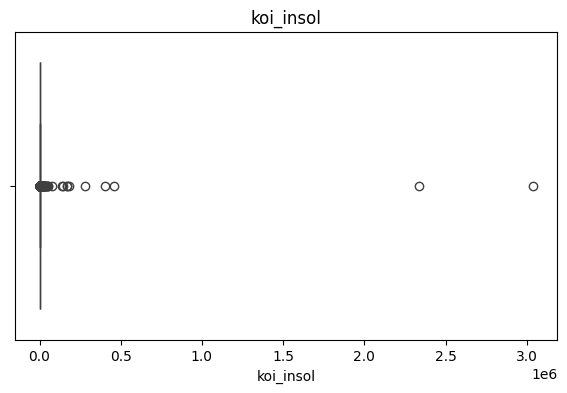

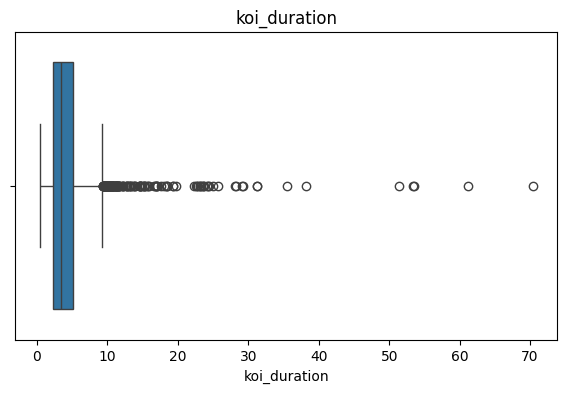

In [24]:
for col in outlier_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=X[col])
    plt.title(col)
    plt.show()

9. Check Missing Values



In [25]:
print(X.isnull().sum()[X.isnull().sum() > 0])

koi_period_err1      35
koi_period_err2      35
koi_time0bk_err1     35
koi_time0bk_err2     35
koi_impact           30
koi_impact_err1      35
koi_impact_err2      35
koi_duration_err1    35
koi_duration_err2    35
koi_depth            30
koi_depth_err1       35
koi_depth_err2       35
koi_prad             30
koi_prad_err1        31
koi_prad_err2        31
koi_teq              31
koi_insol            30
koi_insol_err1       30
koi_insol_err2       30
koi_model_snr        31
koi_tce_plnt_num     85
koi_steff            31
koi_steff_err1       39
koi_steff_err2       48
koi_slogg            31
koi_slogg_err1       39
koi_slogg_err2       39
koi_srad             31
koi_srad_err1        39
koi_srad_err2        39
ra                    1
dec                   1
koi_kepmag            1
dtype: int64


 10. Train-Test Split


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [27]:
y_train.value_counts()

,count
koi_disposition,
CONFIRMED,1149
FALSE POSITIVE,537
CANDIDATE,441


 11. Handle Missing Values


In [28]:
medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Missing values:", X_train.isnull().sum().sum(),
      X_test.isnull().sum().sum())

Missing values: 0 0


12. Handle Outliers



In [29]:
for col in outlier_cols:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (2127, 36)
X_test shape: (532, 36)


 13. Target Encoding


In [30]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

print(encoder.classes_)

['CANDIDATE' 'CONFIRMED' 'FALSE POSITIVE']


In [31]:
import pandas as pd
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy="not majority",
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(pd.Series(y_train).value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE:
1    1149
2     537
0     441
Name: count, dtype: int64

After SMOTE:
1    1149
2    1149
0    1149
Name: count, dtype: int64


## 14. Feature Scaling



In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

##Model Random Forest

## 15. Model Training


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print("Train accuracy:", round(model.score(X_train, y_train), 3))
print("Test accuracy :", round(model.score(X_test, y_test), 3))
print("Test F1       :", round(f1_score(y_test, y_pred, average='weighted'), 3))

              precision    recall  f1-score   support

           0       0.53      0.28      0.36       111
           1       0.75      0.89      0.81       287
           2       0.77      0.77      0.77       134

    accuracy                           0.73       532
   macro avg       0.68      0.65      0.65       532
weighted avg       0.71      0.73      0.71       532

Train accuracy: 1.0
Test accuracy : 0.731
Test F1       : 0.709


## 16. Model Evaluation

In [34]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score

model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print("Train accuracy:", round(model.score(X_train, y_train), 3))
print("Test accuracy :", round(model.score(X_test, y_test), 3))
print("Test F1       :", round(f1_score(y_test, y_pred, average='weighted'), 3))

              precision    recall  f1-score   support

           0       0.47      0.28      0.35       111
           1       0.76      0.89      0.82       287
           2       0.82      0.81      0.82       134

    accuracy                           0.74       532
   macro avg       0.69      0.66      0.66       532
weighted avg       0.72      0.74      0.72       532

Train accuracy: 1.0
Test accuracy : 0.742
Test F1       : 0.722


In [40]:
################################ with cross vaild
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, f1_score
from xgboost import XGBClassifier
import numpy as np

y_encoded = encoder.transform(y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "baseline": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=42
    ),
    "regularized_depth_3": XGBClassifier(
        n_estimators=300, learning_rate=0.03, max_depth=3,
        min_child_weight=5, gamma=0.5,
        reg_alpha=1, reg_lambda=5,
        subsample=0.7, colsample_bytree=0.7,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=42
    ),
    "regularized_depth_4": XGBClassifier(
        n_estimators=300, learning_rate=0.03, max_depth=4,
        min_child_weight=5, gamma=0.5,
        reg_alpha=1, reg_lambda=5,
        subsample=0.7, colsample_bytree=0.7,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=42
    )
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": make_scorer(f1_score, average="macro")
}

for name, estimator in models.items():
    pipeline = make_pipeline(SimpleImputer(strategy="median"), estimator)
    scores = cross_validate(
        pipeline, X, y_encoded, cv=cv, scoring=scoring,
        return_train_score=True, n_jobs=-1
    )

    print(f"\n{name}")
    for metric in ["accuracy", "macro_f1"]:
        train = scores[f"train_{metric}"]
        valid = scores[f"test_{metric}"]
        print(
            f"{metric}: train={train.mean():.3f}, "
            f"validation={valid.mean():.3f}, "
            f"gap={train.mean() - valid.mean():.3f}"
        )


baseline
accuracy: train=1.000, validation=0.749, gap=0.251
macro_f1: train=1.000, validation=0.668, gap=0.332

regularized_depth_3
accuracy: train=0.824, validation=0.744, gap=0.080
macro_f1: train=0.768, validation=0.648, gap=0.120

regularized_depth_4
accuracy: train=0.868, validation=0.749, gap=0.119
macro_f1: train=0.832, validation=0.663, gap=0.169


In [41]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, f1_score
model = VotingClassifier(
    estimators=[
        ("logistic", LogisticRegression(max_iter=2000, class_weight="balanced")),
        ("svm", SVC(kernel="rbf", probability=True, class_weight="balanced")),
        ("tree", DecisionTreeClassifier(max_depth=15, class_weight="balanced")),
        ("forest", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ],
    voting="hard"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Train accuracy:", round(model.score(X_train, y_train), 3))
print("Test accuracy :", round(model.score(X_test, y_test), 3))
print("Test F1       :", round(f1_score(y_test, y_pred, average='weighted'), 3))
print(classification_report(y_test, y_pred))

Train accuracy: 0.86
Test accuracy : 0.68
Test F1       : 0.691
              precision    recall  f1-score   support

           0       0.41      0.56      0.47       111
           1       0.80      0.70      0.75       287
           2       0.77      0.74      0.75       134

    accuracy                           0.68       532
   macro avg       0.66      0.67      0.66       532
weighted avg       0.71      0.68      0.69       532



Train accuracy: 0.7193
Test accuracy : 0.7049
Train F1      : 0.6873
Test F1       : 0.6724
              precision    recall  f1-score   support

           0       0.41      0.18      0.25       111
           1       0.72      0.90      0.80       287
           2       0.78      0.72      0.75       134

    accuracy                           0.70       532
   macro avg       0.63      0.60      0.60       532
weighted avg       0.67      0.70      0.67       532



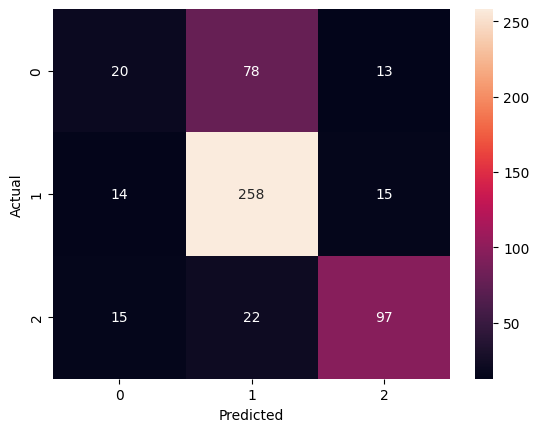

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns
import matplotlib.pyplot as plt

# تدريب الموديل
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_train_pred = model.predict(X_train)
y_pred = model.predict(X_test)

print("Train accuracy:", round(model.score(X_train, y_train), 4))
print("Test accuracy :", round(model.score(X_test, y_test), 4))
print("Train F1      :", round(f1_score(y_train, y_train_pred, average="weighted"), 4))
print("Test F1       :", round(f1_score(y_test, y_pred, average="weighted"), 4))
print(classification_report(y_test, y_pred))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Accuracy: 0.7048872180451128
                precision    recall  f1-score   support

     CANDIDATE       0.41      0.18      0.25       111
     CONFIRMED       0.72      0.90      0.80       287
FALSE POSITIVE       0.78      0.72      0.75       134

      accuracy                           0.70       532
     macro avg       0.63      0.60      0.60       532
  weighted avg       0.67      0.70      0.67       532



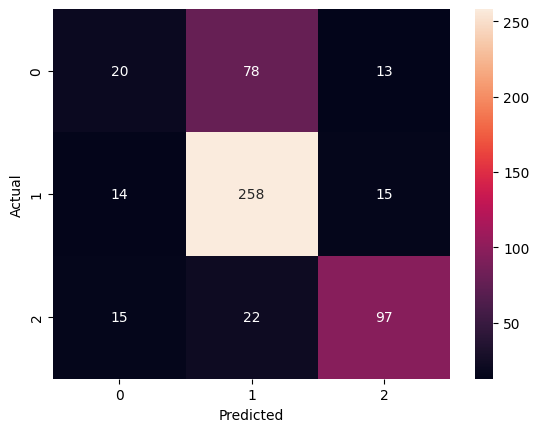

In [50]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [51]:
#gradio
!pip install -q gradio

import os, tempfile
import numpy as np
import pandas as pd
import gradio as gr
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

# ---------- Reuse notebook objects ----------
FEATURES = X.columns.tolist()
CLASSES = encoder.classes_.tolist()

# Clipping bounds (same as step 12; recomputed because they weren't stored)
_Xtr_raw, _, _, _ = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
_Xtr_raw = _Xtr_raw.fillna(medians)
BOUNDS = {}
for c in outlier_cols:
    q1, q3 = _Xtr_raw[c].quantile(0.25), _Xtr_raw[c].quantile(0.75)
    iqr = q3 - q1
    BOUNDS[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# Final model (XGBoost, trained on the already-scaled X_train)
final_model = XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    objective="multi:softprob", eval_metric="mlogloss", random_state=42,
).fit(X_train, y_train)

_pred = final_model.predict(X_test)
ACC = accuracy_score(y_test, _pred)
F1 = f1_score(y_test, _pred, average="weighted")

# ---------- Prediction ----------
def preprocess(df):
    df = df.reindex(columns=FEATURES).apply(pd.to_numeric, errors="coerce").fillna(medians)
    for c, (lo, hi) in BOUNDS.items():
        df[c] = df[c].clip(lo, hi)
    return scaler.transform(df)

def predict_single(*vals):
    row = {c: (np.nan if v is None else v) for c, v in zip(FEATURES, vals)}
    proba = final_model.predict_proba(preprocess(pd.DataFrame([row])))[0]
    return {cls: float(p) for cls, p in zip(CLASSES, proba)}

def predict_batch(file):
    if file is None:
        raise gr.Error("Please upload a CSV file first.")
    df = pd.read_csv(file if isinstance(file, str) else file.name)
    if not set(FEATURES) & set(df.columns):
        raise gr.Error("The file contains none of the required feature columns.")

    proba = final_model.predict_proba(preprocess(df))
    out = df.copy()
    out["prediction"] = [CLASSES[i] for i in proba.argmax(axis=1)]
    out["confidence"] = proba.max(axis=1).round(4)
    for i, cls in enumerate(CLASSES):
        out[f"prob_{cls}"] = proba[:, i].round(4)

    path = os.path.join(tempfile.gettempdir(), "kepler_predictions.csv")
    out.to_csv(path, index=False)
    summary = out["prediction"].value_counts().rename_axis("class").reset_index(name="count")
    return summary, out.head(200), path

# ---------- UI Setup ----------
main_features_dict = {
    "koi_period": "Orbital period (days)",
    "koi_time0bk": "Transit epoch (BKJD)",
    "koi_impact": "Impact parameter",
    "koi_duration": "Transit duration (hrs)",
    "koi_depth": "Transit depth (ppm)",
    "koi_prad": "Planet radius (Earth radii)",
    "koi_teq": "Equilibrium temperature (K)",
    "koi_insol": "Insolation flux (Earth flux)",
    "koi_model_snr": "Transit signal-to-noise",
    "koi_tce_plnt_num": "TCE planet number",
    "koi_steff": "Star temperature (K)",
    "koi_slogg": "Star surface gravity (log10 cm/s²)",
    "koi_srad": "Star radius (Solar radii)",
    "ra": "Right ascension (deg)",
    "dec": "Declination (deg)",
    "koi_kepmag": "Kepler magnitude",
}

main_cols = [c for c in main_features_dict if c in FEATURES]
adv_cols = [c for c in FEATURES if c not in main_cols]
UI_COLS = main_cols + adv_cols

def default(col):
    return float(round(medians[col], 6))

with gr.Blocks(title="Kepler Exoplanet Classifier") as demo:
    gr.Markdown(
        "# 🪐 Kepler Exoplanet Classifier\n"
        "Classifies each KOI as **CONFIRMED / CANDIDATE / FALSE POSITIVE**.\n\n"
        f"**Test accuracy:** {ACC:.3f} · "
        f"**Weighted F1:** {F1:.3f}"
    )

    with gr.Tab("Single Prediction"):
        inputs = []
        with gr.Row():
            half = len(main_cols) // 2
            for chunk in (main_cols[:half], main_cols[half:]):
                with gr.Column():
                    for c in chunk:
                        inputs.append(gr.Number(label=f"{c} — {main_features_dict[c]}", value=default(c)))
        with gr.Accordion("Error columns (optional — defaults to the median)", open=False):
            with gr.Row():
                for i in range(0, len(adv_cols), 10):
                    with gr.Column():
                        for c in adv_cols[i:i + 10]:
                            inputs.append(gr.Number(label=c, value=default(c)))
        btn = gr.Button("Predict", variant="primary")
        label = gr.Label(num_top_classes=3, label="Prediction")
        btn.click(predict_single, inputs=inputs, outputs=label)

    with gr.Tab("Batch Prediction (CSV)"):
        gr.Markdown("Upload a file with the same columns as `cumulative.csv` (missing columns are filled with the median).")
        file_in = gr.File(label="CSV file", file_types=[".csv"])
        run = gr.Button("Predict batch", variant="primary")
        summary = gr.Dataframe(label="Summary")
        preview = gr.Dataframe(label="Preview (first 200 rows)")
        download = gr.File(label="Download predictions")
        run.click(predict_batch, inputs=file_in, outputs=[summary, preview, download])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ff85772099fba90572.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
